In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
train = pd.read_csv("heart_failure_train.csv")

trainCols = {
    "age": "Age of patient (years)",
    "anaemia": "Patient has low red blood cells or haemoglobin (boolean)",
    "creatinine_phosphokinase": "Level of CPK enzyme in blood (mgc/L)",
    "diabetes": "Patient has diabetes (boolean)",
    "ejection_fraction": "% of blood the heart pumps with each beat (%)",
    "high_blood_pressure": "Patient has hypertension (boolean)",
    "platelets": "Platelets in the blood (kiloplatelets/mL)",
    "serum_creatinine": "Creatinine in the blood (a sign of how well the kidneys work) (mg/dL)",
    "serum_sodium": "Sodium in the blood (mEq/L)",
    "sex": "1 = man, 0 = woman",
    "smoking": "Patient smokes (boolean)",
    "time": "How many days the patient was followed (days)",
    "DEATH_EVENT": "What we predict: 1 = died during follow up (boolean)"
}

In [65]:
died = train[train["DEATH_EVENT"] == 1]
survived = train[train["DEATH_EVENT"] == 0]

pValues = {}
mann = {}
chi2 = {}
for column in [c for c in train.columns if c != "DEATH_EVENT"]:
    mann[column] = float(stats.mannwhitneyu(died[column], survived[column]).pvalue)
    chi2[column] = stats.chi2_contingency(pd.crosstab(train[column],train["DEATH_EVENT"]))[1]
    pValues[column] = np.mean([mann[column], chi2[column]])

pValues = pd.Series(dict(sorted(pValues.items(), key = lambda val: val[1])))
pValues

serum_creatinine            0.000009
ejection_fraction           0.000887
time                        0.001046
age                         0.001563
serum_sodium                0.006551
anaemia                     0.404379
platelets                   0.417534
sex                         0.431965
creatinine_phosphokinase    0.465496
smoking                     0.716613
high_blood_pressure         0.840851
diabetes                    0.905517
dtype: float64

In [70]:
keyVars = []
for key in [k for k in pValues.index if k != "time"]:
    if pValues[key] <= 0.05:
        keyVars.append(key)
    else:
        break
keyVars

['serum_creatinine', 'ejection_fraction', 'age', 'serum_sodium']

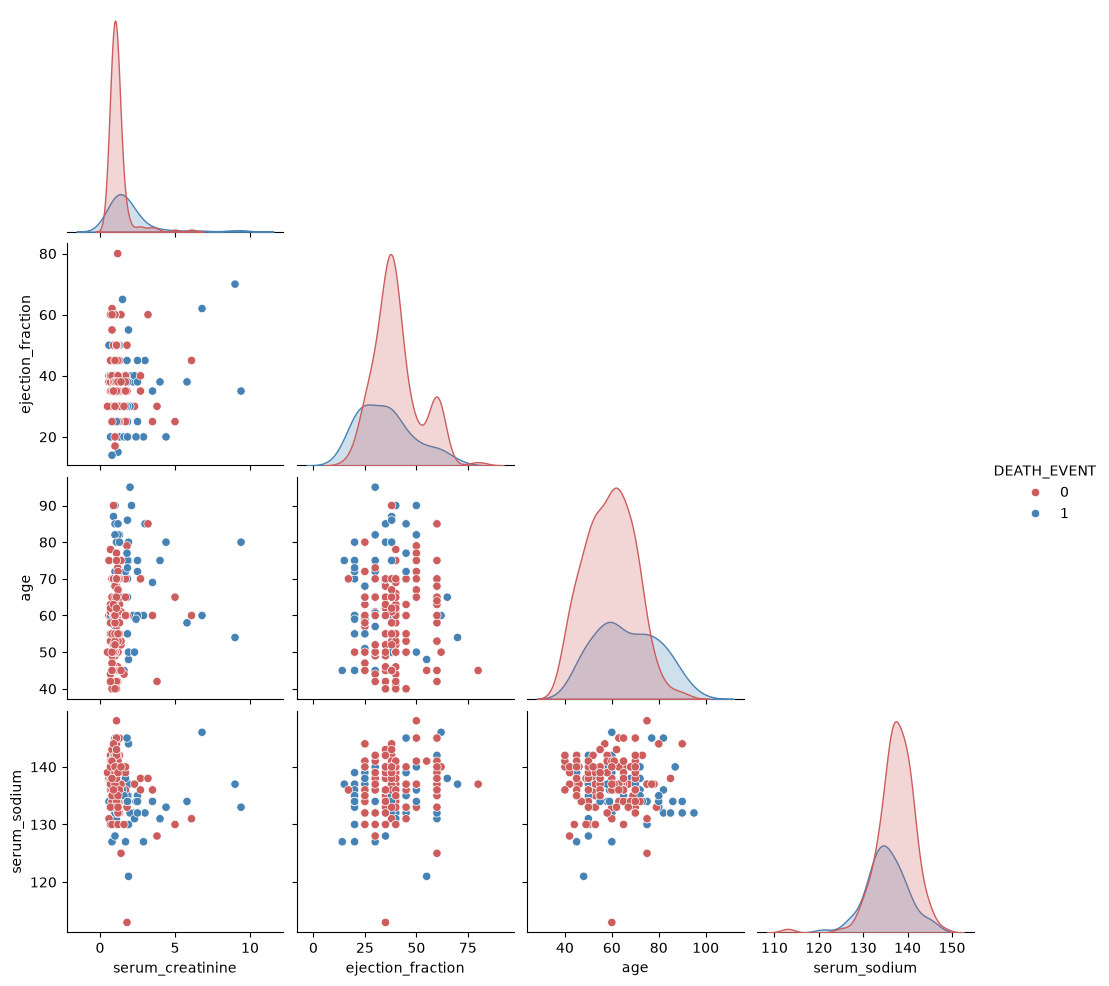

In [84]:
sns.pairplot(
    train, vars = keyVars, hue = "DEATH_EVENT",
    palette = ["indianred", "steelblue"], corner = True
)

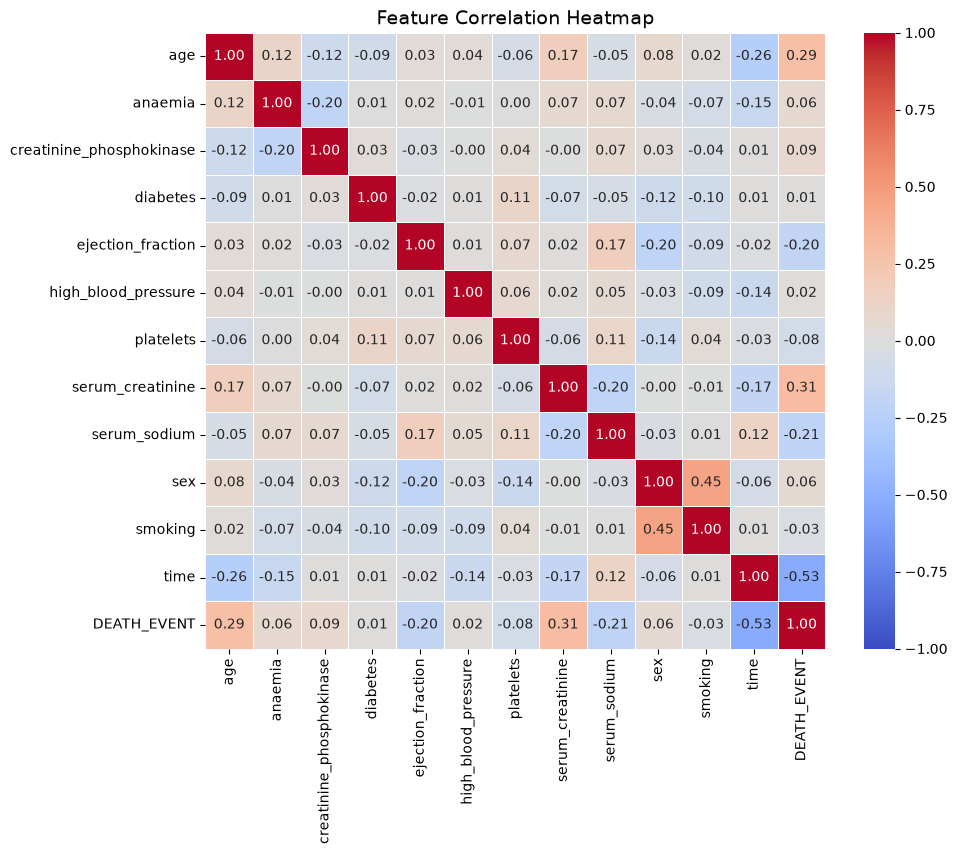

In [85]:
plt.figure(figsize=(10, 8))

# Calculate the correlation matrix
corr_matrix = train.corr()

# Draw the heatmap using seaborn
sns.heatmap(
    corr_matrix, 
    annot=True,          # Shows the actual correlation numbers in the boxes
    fmt=".2f",           # Formats numbers to 2 decimal places
    cmap="coolwarm",     # Red = positive correlation, Blue = negative correlation
    vmin=-1, vmax=1,     # Sets strict bounds for the color scale
    linewidths=0.5       # Adds clean grid lines between cells
)

plt.title("Feature Correlation Heatmap", fontsize=14)
plt.show()

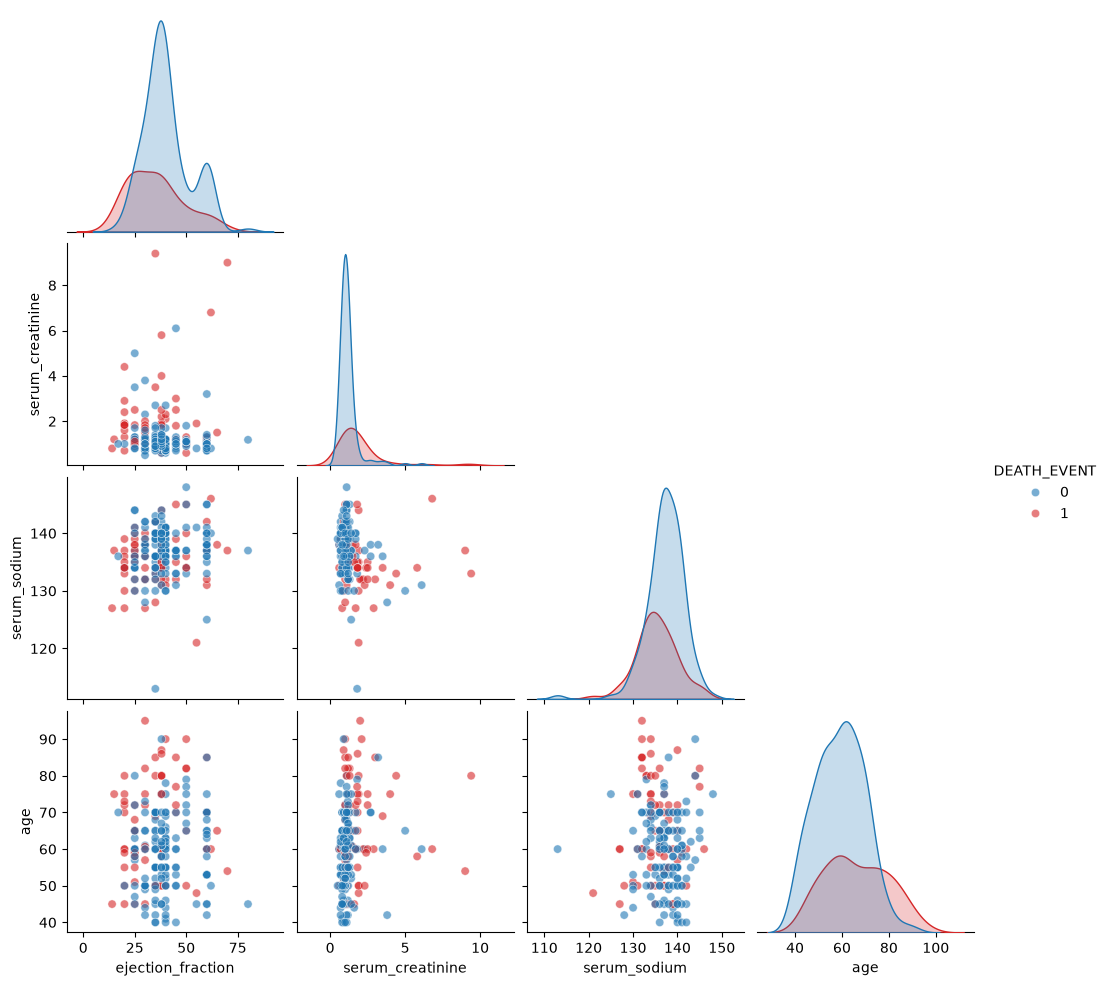

In [69]:
top = ["ejection_fraction", "serum_creatinine", "serum_sodium", "age"]

sns.pairplot(
    train, vars=top, hue="DEATH_EVENT",
    palette={0: "tab:blue", 1: "tab:red"},
    diag_kind="kde", corner=True, plot_kws={"alpha": 0.6}
)
plt.show()

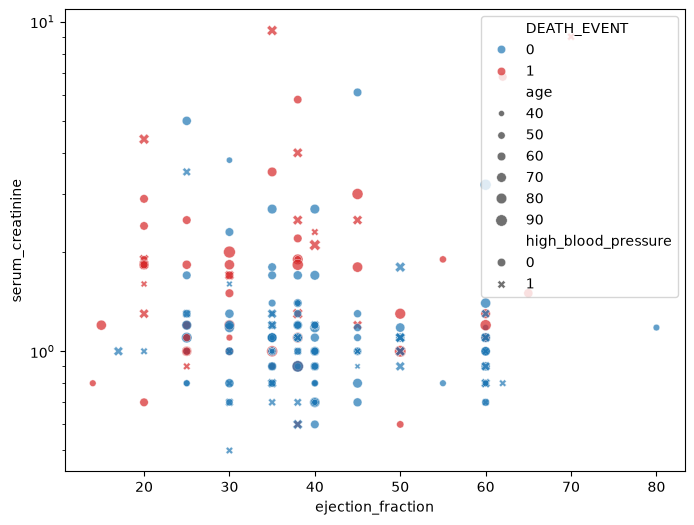

In [67]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=train, x="ejection_fraction", y="serum_creatinine",
    hue="DEATH_EVENT", size="age", style="high_blood_pressure",
    palette={0: "tab:blue", 1: "tab:red"}, alpha=0.7
)
plt.yscale("log")
plt.show()

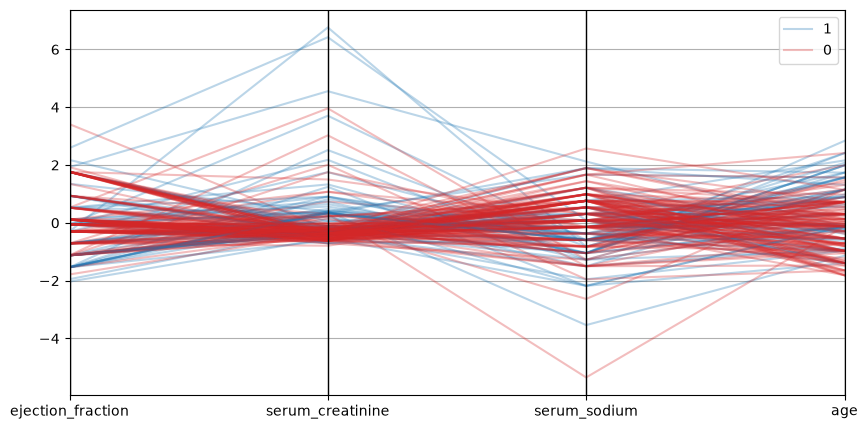

In [57]:
from pandas.plotting import parallel_coordinates

cols = ["ejection_fraction", "serum_creatinine", "serum_sodium", "age"]
scaled = (train[cols] - train[cols].mean()) / train[cols].std()
scaled["DEATH_EVENT"] = train["DEATH_EVENT"]

plt.figure(figsize=(10, 5))
parallel_coordinates(scaled, "DEATH_EVENT", color=["tab:blue", "tab:red"], alpha=0.3)
plt.show()

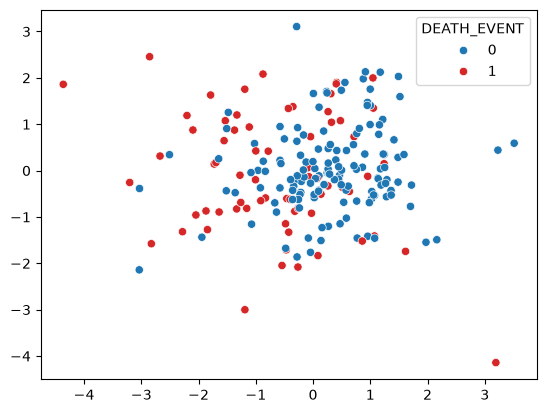

In [58]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

num = ["age", "ejection_fraction", "serum_creatinine", "serum_sodium", "platelets", "creatinine_phosphokinase"]
pcs = PCA(2).fit_transform(StandardScaler().fit_transform(train[num]))

sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=train["DEATH_EVENT"], palette={0: "tab:blue", 1: "tab:red"})
plt.show()